# FastPath on connected market data: the experiments

Reproduces every number in [`docs/FastPath_connected_data.md`](../docs/FastPath_connected_data.md):
baselines, FastPath on event attributes, FastPath on the Moment graph, and the 13F ownership enrichment,
on the 99-asset set (AuraDB) and on the S&P 500 (`gds.graph.construct`).

Prerequisites
- `.env` filled (AuraDB + Aura API credentials, see `.env.example`)
- 99 assets: `scripts/01..04` run (AuraDB loaded), `scripts/05_download_13f.py`, `scripts/06_ownership_graph.py --load`
- S&P 500: `FASTPATH_UNIVERSE=sp500 python scripts/01_download_prices.py --earnings` and `... 02_build_events.py`

Every FastPath run is cached in `results/` (one CSV per setting) and resumable: a first full run takes
about 1 h 30 on a 16 GB session, later runs only read the files.

In [1]:
import os, sys, json, time, importlib, warnings
from pathlib import Path
import certifi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv, find_dotenv
from neo4j import GraphDatabase
from graphdatascience.session import GdsSessions, AuraAPICredentials, DbmsConnectionInfo

warnings.filterwarnings("ignore", category=RuntimeWarning)
os.environ.setdefault("SSL_CERT_FILE", certifi.where())
load_dotenv(find_dotenv(usecwd=True))
os.environ.pop("FASTPATH_UNIVERSE", None)          # start on the 99-asset set
ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import config as C, fp, scoring as S
pd.set_option("display.width", 160)

URI, USER, PASSWORD = os.environ["NEO4J_URI"], os.environ["NEO4J_USERNAME"], os.environ["NEO4J_PASSWORD"]
DATABASE = os.environ.get("NEO4J_DATABASE", "neo4j")
driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
sessions = GdsSessions(api_credentials=AuraAPICredentials(
    os.environ.get("CLIENT_ID") or os.environ["AURA-API-CLIENT-ID"],
    os.environ.get("CLIENT_SECRET") or os.environ["AURA-API-CLIENT-SECRET"],
    os.environ.get("PROJECT_ID") or os.environ.get("AURA_PROJECTID")))
memory = os.environ.get("FASTPATH_SESSION_MEMORY", "16GB")
SESSION_NAME = f"{os.environ.get('FASTPATH_SESSION_NAME', 'fastpath-finance-demo')}-{memory.lower()}"
gds = sessions.get_or_create(session_name=SESSION_NAME, memory=memory, ttl=pd.Timedelta(hours=3).to_pytimedelta(),
                             db_connection=DbmsConnectionInfo(uri=URI, username=USER, password=PASSWORD,
                                 aura_instance_id=os.environ.get("AURA_ID") or os.environ.get("AURA_INSTANCEID")),
                             show_progress=False)
print(driver.execute_query("""RETURN COUNT { (:Asset) } AS assets, COUNT { (:MarketEvent) } AS events,
    COUNT { (:Moment) } AS moments, COUNT { (:Holder) } AS holders, COUNT { ()-[:IN_MOMENT]->() } AS inMoment,
    COUNT { ()-[:HELD_BY]->() } AS heldBy""", database_=DATABASE).records[0].data())

{'assets': 99, 'events': 45639, 'moments': 915, 'holders': 18107, 'inMoment': 11208, 'heldBy': 98331}


## Step 1. Baselines: no FastPath

- `pearson_30d` (the original demo) and `pearson_120d`: trailing correlation of daily log returns
- `same_sector`: GICS sub-industry, then sector
- `co_moment`: Jaccard overlap of the Moments two assets shared in the 180-day look-back (graph only, no returns)
- `co_owned`: correlation of two assets' 13F holder profiles (portfolio weights across managers)
- `co_holder`: Jaccard overlap of the Holder nodes two assets share (the ownership graph as FastPath sees it)

In [2]:
ctx = S.Context()
baselines = [S.pearson(30), S.pearson(120), S.same_sector, S.co_moment, S.co_owned(), S.co_holder]
display(S.evaluate(baselines, ctx))

,dates,fwd_corr@10,fwd_corr@1,hit@10,hedge_err
method,,,,,
oracle,13,0.601,0.728,1.000,0.000
pearson_120d,13,0.512,0.631,0.529,0.097
co_moment,13,0.495,0.613,0.499,0.115
pearson_30d,13,0.471,0.579,0.433,0.149
same_sector,13,0.458,0.570,0.408,0.158
co_owned,13,0.374,0.497,0.282,0.231
co_holder,13,0.369,0.494,0.280,0.234
random,13,0.253,0.252,0.102,0.476


## Step 2. FastPath variants on the 99 assets

One projection per month-end with only the 180 days before it, then `gds.fast_path.mutate`.
`categorical=[]` and `features=False` switch the per-event attributes off, so only the graph context is left.

In [3]:
dates = sorted(r["d"] for r in driver.execute_query("MATCH (s:Snapshot) RETURN DISTINCT s.date AS d",
                                                    database_=DATABASE).records)
EVENTS = dict(decay_rate=0.0, seed=42)                                   # per-event attributes on
CONTEXT = dict(decay_rate=0.0, seed=42, categorical=[], features=False)  # graph context only
VARIANTS = {   # label: (with_moments, with_holders, params)
    "fp events only":                 (False, False, {**EVENTS, "dim": 256}),
    "fp events + moments":            (True,  False, {**EVENTS, "dim": 256}),
    "fp events + holders":            (False, True,  {**EVENTS, "dim": 256}),
    "fp events + moments + holders":  (True,  True,  {**EVENTS, "dim": 256}),
    "fp moments (context only)":      (True,  False, {**CONTEXT, "dim": 256}),
    "fp moments + holders (context)": (True,  True,  {**CONTEXT, "dim": 256}),
    "fp events only, dim 512":        (False, False, {**EVENTS, "dim": 512}),
    "fp connected, dim 512":          (True,  False, {**CONTEXT, "dim": 512}),
}
emb = {}
for label, (mom, hol, P) in VARIANTS.items():
    print(f"{label:<32}", end=" ")
    emb[label] = fp.embed_dates(gds, dates, with_moments=mom, with_holders=hol,
                                cache=fp.cache_name(P, mom, hol), **P)

fp events only                   17 dates cached, 0 to compute
fp events + moments              17 dates cached, 0 to compute
fp events + holders              17 dates cached, 0 to compute
fp events + moments + holders    17 dates cached, 0 to compute
fp moments (context only)        

17 dates cached, 0 to compute
fp moments + holders (context)   17 dates cached, 0 to compute
fp events only, dim 512          17 dates cached, 0 to compute
fp connected, dim 512            

17 dates cached, 0 to compute


## Step 3. Scores, 99 assets (13 month-ends with a full 60-day forward window)

,dates,fwd_corr@10,fwd_corr@1,hit@10,hedge_err
method,,,,,
oracle,13,0.601,0.728,1.000,0.000
pearson_120d,13,0.512,0.631,0.529,0.097
co_moment,13,0.495,0.613,0.499,0.115
"fp connected, dim 512",13,0.488,0.607,0.484,0.121
fp moments (context only),13,0.481,0.598,0.472,0.130
pearson_30d,13,0.471,0.579,0.433,0.149
same_sector,13,0.458,0.570,0.408,0.158
fp moments + holders (context),13,0.405,0.513,0.340,0.215
fp events + moments,13,0.399,0.542,0.335,0.186


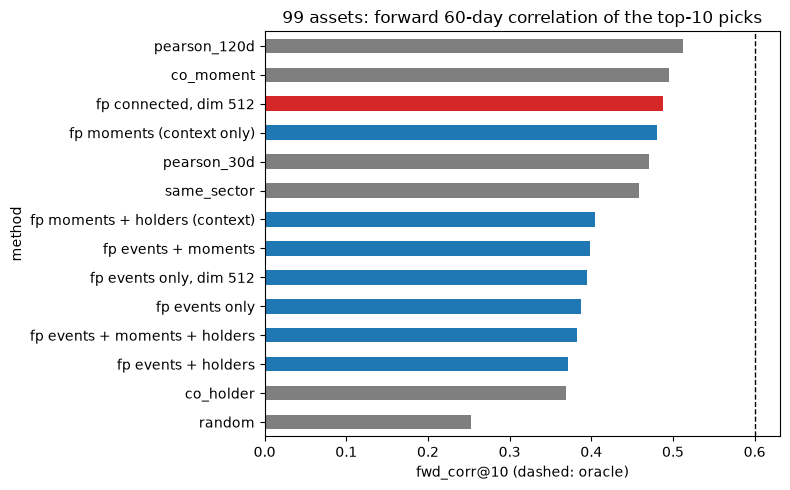

In [4]:
summary99, per_date99 = S.evaluate([S.pearson(30), S.pearson(120), S.same_sector, S.co_moment, S.co_holder]
                                  + [S.embeddings(e, n) for n, e in emb.items()], ctx, per_date=True)
display(summary99)
k = f"fwd_corr@{C.TOP_K}"
ax = summary99[k].drop(["oracle"]).sort_values().plot.barh(figsize=(8, 5), color=[
    "#d62728" if "connected" in i else "#1f77b4" if i.startswith("fp") else "#7f7f7f"
    for i in summary99[k].drop(["oracle"]).sort_values().index])
ax.axvline(summary99.loc["oracle", k], ls="--", c="k", lw=1); ax.set_xlabel(f"{k} (dashed: oracle)")
ax.set_title("99 assets: forward 60-day correlation of the top-10 picks"); plt.tight_layout(); plt.show()

## Step 4. Same test on the S&P 500

The S&P 500 is not loaded in AuraDB: `construct=True` builds each as-of graph from `data/sp500/built` in pandas
(same nodes and relationships as the Cypher projection) and sends it with `gds.graph.construct`.

In [5]:
os.environ["FASTPATH_UNIVERSE"] = "sp500"
for m in (C, fp, S):
    importlib.reload(m)
dates500 = sorted(pd.read_csv(C.BUILT / "snapshots.csv")["date"].unique())
emb500 = {}
for label in ["fp events only, dim 512", "fp connected, dim 512"]:
    mom, hol, P = VARIANTS[label]
    print(f"{label:<32}", end=" ")
    emb500[label] = fp.embed_dates(gds, dates500, with_moments=mom, construct=True,
                                   cache=fp.cache_name(P, mom), **P)
ctx500 = S.Context()
summary500 = S.evaluate([S.pearson(30), S.pearson(120), S.same_sector, S.co_moment, S.co_owned(), S.co_holder]
                        + [S.embeddings(e, n) for n, e in emb500.items()], ctx500)
display(summary500)
os.environ.pop("FASTPATH_UNIVERSE")
for m in (C, fp, S):
    importlib.reload(m)

fp events only, dim 512          

40 dates cached, 0 to compute
fp connected, dim 512            

40 dates cached, 0 to compute


,dates,fwd_corr@10,fwd_corr@1,hit@10,hedge_err
method,,,,,
oracle,36,0.621,0.731,1.000,0.000
pearson_120d,36,0.470,0.588,0.299,0.143
co_moment,36,0.440,0.563,0.265,0.168
"fp connected, dim 512",36,0.430,0.551,0.250,0.180
pearson_30d,36,0.415,0.519,0.225,0.212
same_sector,36,0.399,0.498,0.218,0.233
"fp events only, dim 512",36,0.329,0.425,0.138,0.306
co_owned,36,0.324,0.384,0.130,0.347
co_holder,36,0.321,0.398,0.124,0.333


## Step 5. What the graph adds

In [6]:
for name, sm in [("99 assets", summary99), ("S&P 500", summary500)]:
    con, ev = sm.loc["fp connected, dim 512", k], sm.loc["fp events only, dim 512", k]
    print(f"{name:<10} events only {ev:.3f} -> connected {con:.3f} ({con / ev - 1:+.0%})   "
          f"vs pearson_30d {con - sm.loc['pearson_30d', k]:+.3f}   vs pearson_120d {con - sm.loc['pearson_120d', k]:+.3f}")

99 assets  events only 0.395 -> connected 0.488 (+24%)   vs pearson_30d +0.017   vs pearson_120d -0.024
S&P 500    events only 0.329 -> connected 0.430 (+31%)   vs pearson_30d +0.015   vs pearson_120d -0.040


In [7]:
DELETE_SESSION = False   # True to stop billing
if DELETE_SESSION:
    gds.delete(); print("session deleted")